# 07 · Rehearsal (TCGA → METABRIC)

Fine-tuning (strategy 2) and the network from scratch (strategy 3) need a **learning rate** and a **number of epochs**. They cannot be chosen with CPTAC or SMC, because that would be choosing with the exam. With 10 patients there are also not enough patients to set aside for validation.

The solution is to **rehearse the whole experiment inside the source**. A network is trained only with **TCGA**, and **METABRIC** is used as if it were a new cohort. TCGA is RNA-seq and METABRIC is a microarray, so the jump looks like the jump from the source to CPTAC and SMC. Whatever works best here is frozen and used as it is in notebook 08. This rehearsal also tests the code before CPTAC and SMC are touched. They are **not loaded** in this notebook.

Both strategies test **the same number of combinations**, so that neither one has an advantage (Hanczar et al. 2022).

**Input:** the source data, `06_elegida.json` (shape of the network) and `elasticnet_fuente.joblib` (mix and strength of ElasticNet, notebook 05).
**Output:** `data/experiment/ensayo_auc.csv` (AUC on the exam and on the network's own local patients), `data/experiment/ensayo_curvas.parquet` (loss and AUC per epoch), `results/tables/07_ajuste_elegido.json` and `07_resumen.csv`.

**Time:** about 2 hours on the Khipu cluster. It saves after each exam.

*Note: this notebook was run before the repository was translated. The code comments, printed text and figure labels in the saved outputs are in Spanish. The results are the same.*

In [1]:
import json
import sys
import time
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import train_test_split

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "scripts"))
from common import armar_red, cargar, pesos_clase, zscore  # common sets Keras to run on PyTorch before keras is imported

import keras

EXP = ROOT / "data" / "experiment"
FIG = ROOT / "results" / "figures"
TAB = ROOT / "results" / "tables"
PARTS = EXP / "partes_07"
PARTS.mkdir(exist_ok=True)

N_LOCAL, N_EXAM, N_EXAMS, N_REPS = [10, 15, 20, 40], 40, 5, 20
RATES = {2: [1e-5, 1e-4, 1e-3], 3: [1e-4, 1e-3, 1e-2]}
EPOCHS = [10, 30, 100]
NAMES = {1: "1. Red: aplicar directo", 2: "2. Ajuste fino", 3: "3. Desde cero", 4: "4. ElasticNet: aplicar directo"}
COLORS = {2: "#534AB7", 3: "#D85A30"}
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

arch = json.loads((TAB / "06_elegida.json").read_text())
arch

{'capas': [256],
 'tasa': 0.0003,
 'lote': 16,
 'dropout': 0.3,
 'optimizador': 'sgd',
 'epocas': 19,
 'auc_validacion': 0.9431}

## Step 1 · Network pretrained only with TCGA

- TCGA is normalized with its own mean and SD (961 patients).
- Same network as notebook 06 (`06_elegida.json`).
- To know how many epochs to train, 20% of TCGA is set aside as validation and early stopping is used (patience 10). Then the network is trained with all TCGA for that number of epochs, like the final network of notebook 06.

In [2]:
x_tcga, y_tcga = cargar("TCGA-BRCA")
X_t, y_t = zscore(x_tcga, x_tcga.index).to_numpy(), y_tcga.to_numpy()

tr, va = train_test_split(np.arange(len(y_t)), test_size=0.2, stratify=y_t, random_state=2026)
keras.utils.set_random_seed(2026)
probe = armar_red(arch["capas"], arch["dropout"], arch["tasa"], arch["optimizador"])
h = probe.fit(X_t[tr], y_t[tr], batch_size=arch["lote"], epochs=200, validation_data=(X_t[va], y_t[va]),
              class_weight=pesos_clase(y_t[tr]), verbose=0,
              callbacks=[keras.callbacks.EarlyStopping(monitor="val_auc", mode="max", patience=10)]).history
tcga_epochs = int(np.argmax(h["val_auc"])) + 1

keras.utils.set_random_seed(2026)
pretrained = armar_red(arch["capas"], arch["dropout"], arch["tasa"], arch["optimizador"])
pretrained.fit(X_t, y_t, batch_size=arch["lote"], epochs=tcga_epochs, class_weight=pesos_clase(y_t), verbose=0)
pre_weights = pretrained.get_weights()
print(f"Red de TCGA: {tcga_epochs} épocas · AUC de validación {max(h['val_auc']):.3f}")

Red de TCGA: 6 épocas · AUC de validación 0.959


## Step 2 · Reference: ElasticNet only with TCGA

With the mix and strength chosen in notebook 05. It is the second "apply directly" line.

In [3]:
enet_src = joblib.load(EXP / "elasticnet_fuente.joblib")
enet_tcga = LogisticRegression(penalty="elasticnet", solver="saga", l1_ratio=enet_src.l1_ratio, C=enet_src.C,
                               max_iter=1000, tol=1e-3, random_state=0).fit(X_t, y_t)
print(f"ElasticNet de TCGA: mezcla {enet_src.l1_ratio}, fuerza {enet_src.C}")

ElasticNet de TCGA: mezcla 0.9, fuerza 0.05


## Step 3 · The rehearsal in METABRIC

Same design as notebook 04, but inside METABRIC (1,899 patients):
- 5 exams of 40 patients, stratified by TP53 (seeds 2026–2030).
- n = 10, 15, 20 and 40 local patients, with **20 repetitions** per n and exam (not 100, because here we only choose, we do not report). Seeds as in notebook 04.
- METABRIC is normalized with the patients outside each exam.

Combinations:

| Strategy | Learning rate | Epochs |
|---|---|---|
| 2. Fine-tuning (every layer free) | 1e-5, 1e-4, 1e-3 | 10, 30, 100 |
| 3. From scratch (same network, new weights) | 1e-4, 1e-3, 1e-2 | 10, 30, 100 |

1. Fine-tuning uses smaller learning rates because it starts from a network that already knows something. Big steps would erase it.
2. **Batch = all n local patients together.** With 10 patients it makes no sense to split them.
3. **Network seed = repetition number**, the same for strategies 2 and 3.
4. **One training run per learning rate.** The network is trained for 100 epochs and measured at epochs 10, 30 and 100. It is the same as training 10, 30 and 100 epochs separately (same seed, same batch, fixed learning rate), with one third of the computation.
5. At those epochs the AUC is measured **on the exam** and **on the network's own local patients**. The difference between the two (the **gap**) shows how much the network memorized.

In [4]:
class Snapshots(keras.callbacks.Callback):
    """AUC exacto en el examen y con los pacientes locales al final de las épocas 10, 30 y 100."""

    def __init__(self, x_loc, y_loc, x_exam, y_exam):
        super().__init__()
        self.data, self.out = (x_loc, y_loc, x_exam, y_exam), {}

    def on_epoch_end(self, epoch, logs=None):
        if epoch + 1 in EPOCHS:
            x_loc, y_loc, x_exam, y_exam = self.data
            self.out[epoch + 1] = (roc_auc_score(y_exam, self.model.predict(x_exam, verbose=0).ravel()),
                                   roc_auc_score(y_loc, self.model.predict(x_loc, verbose=0).ravel()))


def train(strategy, rate, rep, x_loc, y_loc, x_exam, y_exam):
    keras.utils.set_random_seed(rep)
    model = armar_red(arch["capas"], arch["dropout"], rate, arch["optimizador"])
    if strategy == 2:
        model.set_weights(pre_weights)
    snap = Snapshots(x_loc, y_loc, x_exam, y_exam)
    h = model.fit(x_loc, y_loc, batch_size=len(y_loc), epochs=max(EPOCHS), validation_data=(x_exam, y_exam),
                  class_weight=pesos_clase(y_loc), callbacks=[snap], verbose=0).history
    return snap.out, h

In [5]:
x_meta, y_meta = cargar("METABRIC")
y_m = y_meta.to_numpy()

for e in range(N_EXAMS):
    part = PARTS / f"examen{e + 1}.parquet"
    if part.exists():
        continue
    start = time.time()
    rest, exam = train_test_split(np.arange(len(y_m)), test_size=N_EXAM, stratify=y_m, random_state=2026 + e)
    z = zscore(x_meta, x_meta.index[rest]).to_numpy()
    x_exam, y_exam = z[exam], y_m[exam]
    aucs = [{"examen": e + 1, "estrategia": 1, "n": 0, "auc": roc_auc_score(y_exam, pretrained.predict(x_exam, verbose=0).ravel())},
            {"examen": e + 1, "estrategia": 4, "n": 0, "auc": roc_auc_score(y_exam, enet_tcga.decision_function(x_exam))}]
    curves = []
    for n in N_LOCAL:
        for r in range(N_REPS):
            loc, _ = train_test_split(rest, train_size=n, stratify=y_m[rest], random_state=100000 * e + 1000 * n + r)
            for s, rates in RATES.items():
                for rate in rates:
                    out, h = train(s, rate, r, z[loc], y_m[loc], x_exam, y_exam)
                    aucs += [{"examen": e + 1, "estrategia": s, "tasa": rate, "epocas": ep, "n": n, "repeticion": r,
                              "auc": a, "auc_locales": a_loc} for ep, (a, a_loc) in out.items()]
                    curves.append(pd.DataFrame({"examen": e + 1, "estrategia": s, "tasa": rate, "n": n, "repeticion": r,
                                                "epoca": np.arange(1, max(EPOCHS) + 1), "perdida": h["loss"],
                                                "perdida_examen": h["val_loss"], "auc_examen": h["val_auc"]}))
    pd.DataFrame(aucs).to_parquet(part)
    pd.concat(curves).to_parquet(PARTS / f"curvas_examen{e + 1}.parquet")
    print(f"Examen {e + 1}: {(time.time() - start) / 60:.0f} min")

Examen 1: 24 min


Examen 2: 23 min


Examen 3: 25 min


Examen 4: 23 min


Examen 5: 25 min


## Step 4 · Join and choose

For each strategy, the combination of learning rate and epochs with the highest **mean AUC on the exam** is chosen (all n and the 5 exams together). If another one is less than 0.005 below, the one with the smaller SD across repetitions is chosen. The same combination is used for every n.

In [6]:
auc = pd.concat([pd.read_parquet(p) for p in sorted(PARTS.glob("examen*.parquet"))], ignore_index=True)
curves = pd.concat([pd.read_parquet(p) for p in sorted(PARTS.glob("curvas_*.parquet"))], ignore_index=True)
auc.to_csv(EXP / "ensayo_auc.csv", index=False)
curves.to_parquet(EXP / "ensayo_curvas.parquet")

nets = auc[auc.estrategia.isin([2, 3])]
per_exam = nets.groupby(["estrategia", "tasa", "epocas", "n", "examen"]).auc.agg(["mean", "std"])
summary = (per_exam.groupby(["estrategia", "tasa", "epocas", "n"]).mean()
           .rename(columns={"mean": "AUC promedio", "std": "DE entre repeticiones"}).round(4))
summary.to_csv(TAB / "07_resumen.csv")

grid = summary.groupby(["estrategia", "tasa", "epocas"]).mean()
chosen = {}
for s in (2, 3):
    g = grid.loc[s]
    near = g[g["AUC promedio"] >= g["AUC promedio"].max() - 0.005]
    rate, epochs = near["DE entre repeticiones"].idxmin()
    chosen[s] = {"tasa": float(rate), "epocas": int(epochs), "auc_promedio": float(g.loc[(rate, epochs), "AUC promedio"])}
(TAB / "07_ajuste_elegido.json").write_text(json.dumps({"ajuste_fino": chosen[2], "desde_cero": chosen[3],
                                                        "epocas_red_tcga": tcga_epochs}, indent=2))
chosen

{2: {'tasa': 1e-05, 'epocas': 10, 'auc_promedio': 0.864625},
 3: {'tasa': 0.001, 'epocas': 100, 'auc_promedio': 0.77795}}

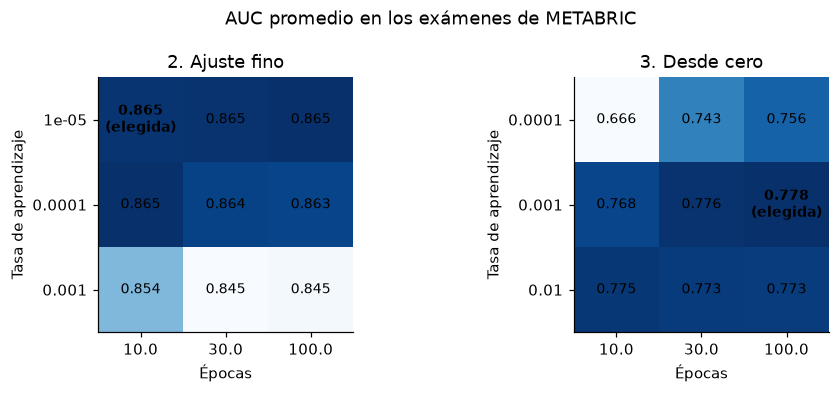

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.6))
for ax, s in zip(axes, (2, 3)):
    heat = grid.loc[s]["AUC promedio"].unstack("epocas")
    ax.imshow(heat, cmap="Blues")
    for i, rate in enumerate(heat.index):
        for j, ep in enumerate(heat.columns):
            mark = rate == chosen[s]["tasa"] and ep == chosen[s]["epocas"]
            ax.text(j, i, f"{heat.loc[rate, ep]:.3f}" + ("\n(elegida)" if mark else ""), ha="center", va="center",
                    fontweight="bold" if mark else "normal", fontsize=9)
    ax.set_xticks(range(len(heat.columns)), heat.columns)
    ax.set_yticks(range(len(heat.index)), heat.index)
    ax.set_xlabel("Épocas")
    ax.set_ylabel("Tasa de aprendizaje")
    ax.set_title(NAMES[s])
fig.suptitle("AUC promedio en los exámenes de METABRIC")
plt.tight_layout()
fig.savefig(FIG / "07_rejilla.png", bbox_inches="tight")

**How to read it:** each cell is the mean AUC on the exam (all n and exams). A flat area means the choice is not delicate. A single high cell surrounded by low ones would be suspicious. If the chosen one is on an edge (extreme learning rate or epochs), the grid may need to be wider.

**What happened:** no fine-tuning setting gave a higher AUC than applying the network directly (all between 0.845 and 0.865, against 0.864). Since they tied, the tie-break (smallest SD) chose the setting that changes the network the least (learning rate 1e-5, 10 epochs). That is why notebook 08 also runs a sensitivity setting with learning rate 1e-4.

## Step 5 · The rehearsal with the chosen combinations

In [8]:
best = pd.concat([nets[(nets.estrategia == s) & (nets.tasa == c["tasa"]) & (nets.epocas == c["epocas"])]
                  for s, c in chosen.items()])
best_summary = (best.assign(brecha=best.auc_locales - best.auc)
                .groupby(["estrategia", "n", "examen"]).agg(auc=("auc", "mean"), de=("auc", "std"), brecha=("brecha", "mean"))
                .groupby(["estrategia", "n"]).mean())
refs = auc[auc.estrategia.isin([1, 4])].groupby("estrategia").auc.mean()
print("Aplicar directo (promedio de 5 exámenes):", {NAMES[k]: round(v, 3) for k, v in refs.items()})
best_summary.round(3)

Aplicar directo (promedio de 5 exámenes): {'1. Red: aplicar directo': 0.864, '4. ElasticNet: aplicar directo': 0.918}


auc     de  brecha
estrategia n                       
2          10  0.865  0.002   0.092
           15  0.865  0.002   0.077
           20  0.864  0.002   0.078
           40  0.865  0.001   0.053
3          10  0.750  0.086   0.250
           15  0.769  0.080   0.231
           20  0.782  0.065   0.218
           40  0.811  0.044   0.189

**Published reference:** STAMP moved its TCGA model to METABRIC and got 0.902 with its graph network and 0.841 with ElasticNet. If our "apply directly" were much lower, something would have to be checked before going on.

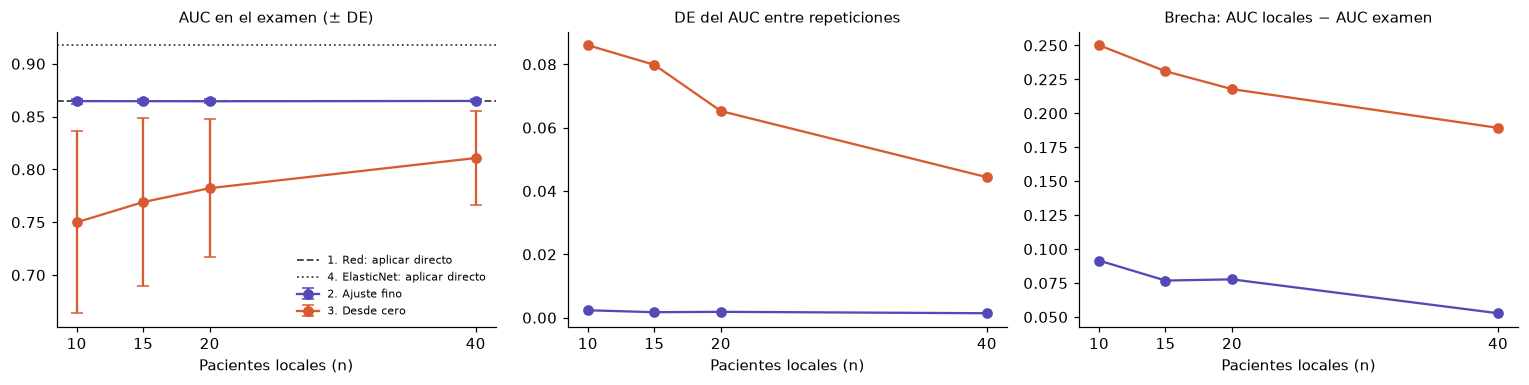

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.6))
for s in (2, 3):
    t = best_summary.loc[s]
    axes[0].errorbar(t.index, t.auc, yerr=t.de, marker="o", capsize=4, color=COLORS[s], label=NAMES[s])
    axes[1].plot(t.index, t.de, marker="o", color=COLORS[s], label=NAMES[s])
    axes[2].plot(t.index, t.brecha, marker="o", color=COLORS[s], label=NAMES[s])
for k, ls in ((1, "--"), (4, ":")):
    axes[0].axhline(refs[k], color="#444441", ls=ls, lw=1.2, label=NAMES[k])
titles = ["AUC en el examen (± DE)", "DE del AUC entre repeticiones", "Brecha: AUC locales − AUC examen"]
for ax, title in zip(axes, titles):
    ax.set_title(title, fontsize=10)
    ax.set_xlabel("Pacientes locales (n)")
    ax.set_xticks(N_LOCAL)
axes[0].legend(frameon=False, fontsize=7, loc="lower right")
plt.tight_layout()
fig.savefig(FIG / "07_auc_de_brecha_vs_n.png", bbox_inches="tight")

**How to read it** (a preview of notebook 08, but in METABRIC):
- **Left:** if the pretrained network does not reach a higher AUC than applying it directly, even with 40 patients, fine-tuning may not help in CPTAC and SMC either.
- **Center:** the main question of the study. Does the pretrained network vary less than the network from scratch?
- **Right:** the **gap** between the AUC on the network's own local patients and the AUC on the exam. A big gap means that the network memorized its few patients (overfitting). The gap is expected to go down as n grows.

## Step 6 · Curves per epoch

With the chosen learning rate of each strategy: loss on the local patients and on the exam, and AUC on the exam, epoch by epoch. Mean of all repetitions and exams; band = ± SD. The vertical line marks the chosen epochs.

The exam can be looked at here because it is METABRIC (part of the source). CPTAC and SMC are not touched.

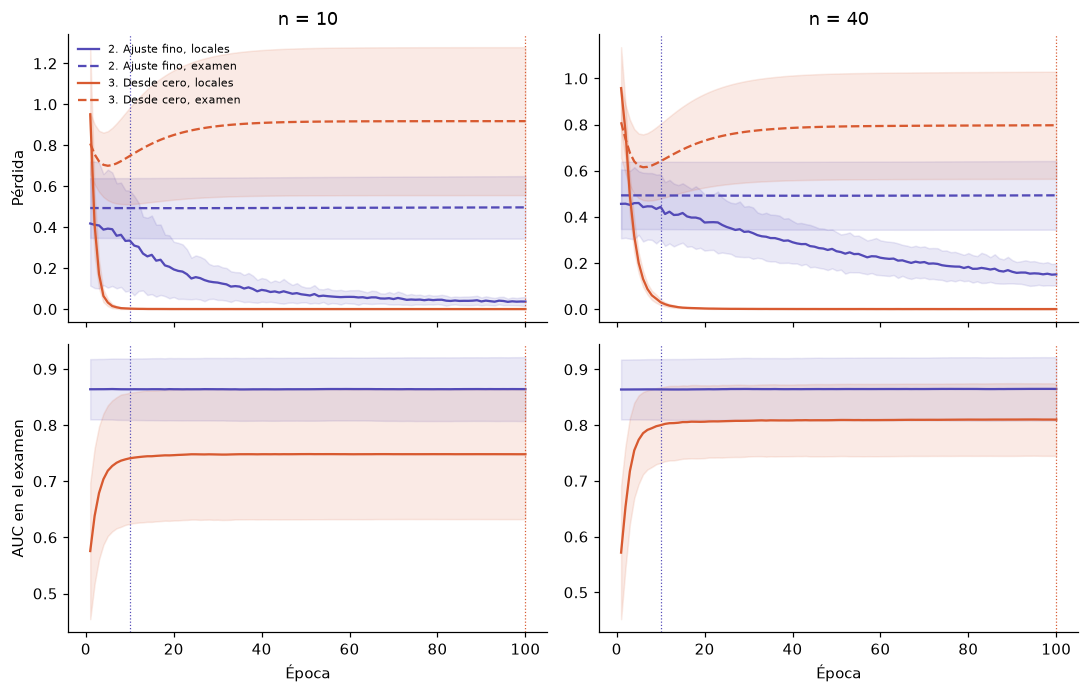

In [10]:
fig, axes = plt.subplots(2, 2, figsize=(10, 6.4), sharex=True)
for col, n in enumerate([10, 40]):
    for s, c in chosen.items():
        d = curves[(curves.estrategia == s) & (curves.tasa == c["tasa"]) & (curves.n == n)].groupby("epoca")
        for row, (cols, styles) in enumerate([(["perdida", "perdida_examen"], ["-", "--"]), (["auc_examen"], ["-"])]):
            for var, ls in zip(cols, styles):
                m, sd = d[var].mean(), d[var].std()
                axes[row, col].plot(m.index, m, ls=ls, color=COLORS[s],
                                    label=f"{NAMES[s]}, {'locales' if var == 'perdida' else 'examen'}" if row == 0 else NAMES[s])
                axes[row, col].fill_between(m.index, m - sd, m + sd, color=COLORS[s], alpha=0.12)
            axes[row, col].axvline(c["epocas"], color=COLORS[s], lw=0.8, ls=":")
    axes[0, col].set_title(f"n = {n}")
    axes[1, col].set_xlabel("Época")
axes[0, 0].set_ylabel("Pérdida")
axes[1, 0].set_ylabel("AUC en el examen")
axes[0, 0].legend(frameon=False, fontsize=7)
plt.tight_layout()
fig.savefig(FIG / "07_curvas_epocas.png", bbox_inches="tight")

**How to read it:** solid line = loss on the local patients (training); dashed line = loss on the exam. While the exam loss goes down, the network learns something that also works outside its own patients. When the training loss keeps going down and the exam loss goes up, the network starts to memorize. The network from scratch memorizes in about 5 epochs. With fine-tuning, the training loss goes down but the exam AUC does not move.

The AUC per epoch is computed by Keras in an approximate way. The AUCs in the tables are exact (scikit-learn).